# Example of the aitlas toolbox in the context of semantic segmentation

## Import the required packages

In [ ]:
from aitlas.datasets import AI4SmallFarmsDataset
from aitlas.utils import image_loader
from aitlas.models import DeepLabV3
from aitlas.transforms import MinMaxNormTranspose

## Visualize images and masks

Total number of patches: 43


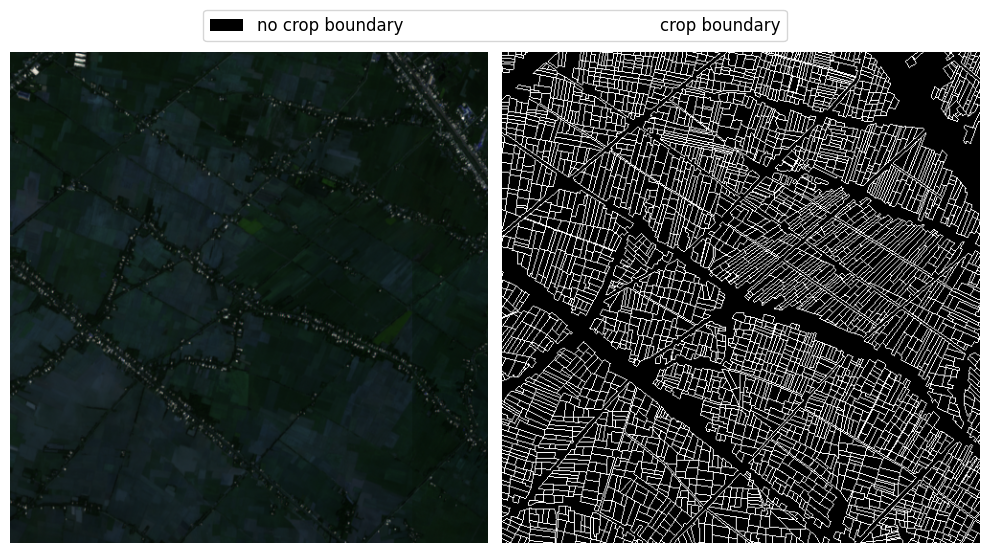

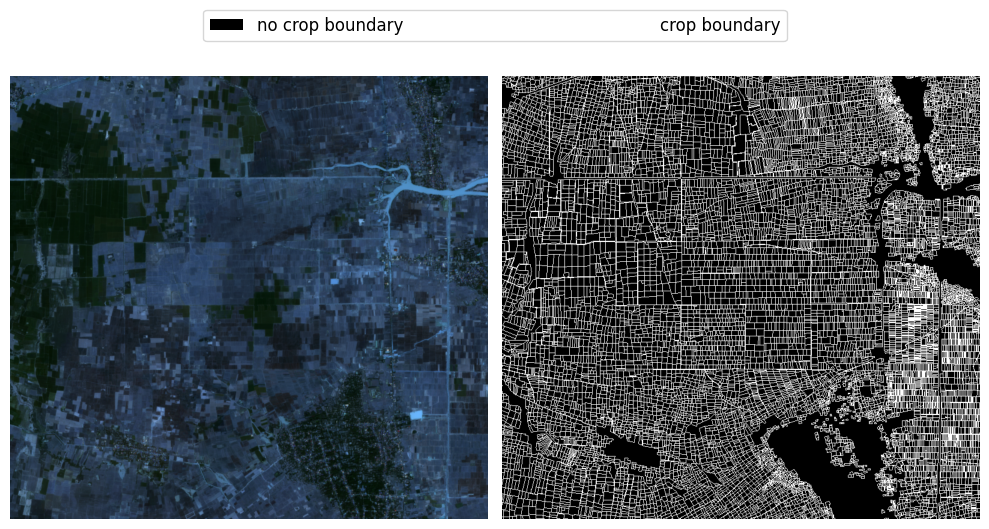

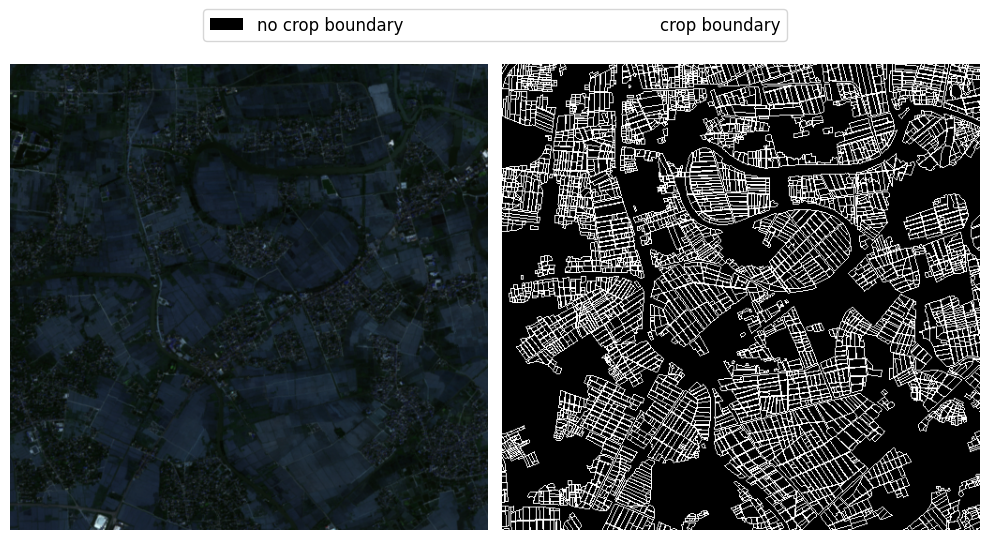

In [18]:
dataset_config = {
    "data_dir": "/home/dragik/data/FAIR_EO/ai4smallfarms/sentinel-2-asia/train"
}
dataset = AI4SmallFarmsDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")
dataset.show_image(1);
dataset.show_image(3);
dataset.show_image(8);

In [11]:
dataset.data_distribution_table()

,Number of pixels
no crop boundary,9144106.0
crop boundary,3518041.0


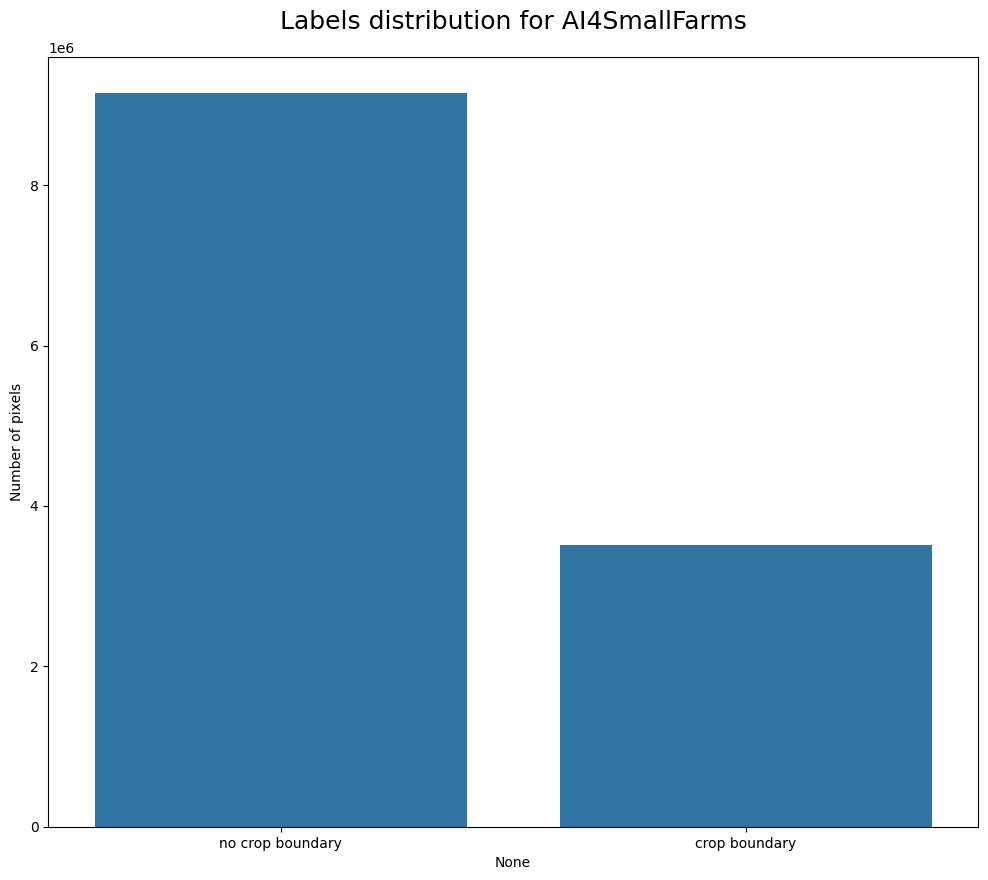

In [12]:
dataset.data_distribution_barchart();

## Load training data

In [9]:
train_dataset_config = {
    "batch_size": 4,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "/home/dragik/data/FAIR_EO/ai4smallfarms/sentinel-2-asia/train",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}
train_dataset = AI4SmallFarmsDataset(train_dataset_config)
len(train_dataset)

43

## Create the model

In [10]:
epochs = 50
model_directory = "/home/dragik/data/FAIR_EO/experiments/ai4smallfarms"
model_config = {
    "num_classes": 2, 
    "learning_rate": 0.0001,
    "pretrained": True, 
    "threshold": 0.5,
    "metrics": ["iou"]
}

model = DeepLabV3(model_config)
model.prepare()

## Start the training

In [11]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
);

2025-11-12 13:55:13,182 INFO Starting training.
training: 100%|██████████| 11/11 [00:11<00:00,  1.04s/it]
2025-11-12 13:55:24,650 INFO epoch: 1, time: 11, loss:  0.49600
testing on train set: 100%|██████████| 11/11 [00:11<00:00,  1.01s/it]
2025-11-12 13:55:38,215 INFO IOU:0.0696327200601874, IOU mean:0.07942563890698204, IOU per Class:[0.15858929 0.00026199]
training: 100%|██████████| 11/11 [00:11<00:00,  1.04s/it]
2025-11-12 13:55:49,643 INFO epoch: 2, time: 11, loss:  0.45826
testing on train set: 100%|██████████| 11/11 [00:11<00:00,  1.02s/it]
2025-11-12 13:56:00,828 INFO IOU:0.07602749741482247, IOU mean:0.09217308633520975, IOU per Class:[0.184074   0.00027217]
training: 100%|██████████| 11/11 [00:12<00:00,  1.13s/it]
2025-11-12 13:56:13,245 INFO epoch: 3, time: 13, loss:  0.42873
testing on train set: 100%|██████████| 11/11 [00:12<00:00,  1.11s/it]
2025-11-12 13:56:25,430 INFO IOU:0.19052460491401568, IOU mean:0.09529801367363591, IOU per Class:[0.19059603 0.        ]
training: 1

## Evaluate the model

In [12]:
test_dataset_config = {
    "batch_size": 4,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "/home/dragik/data/FAIR_EO/ai4smallfarms/sentinel-2-asia/validate",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}

test_dataset = AI4SmallFarmsDataset(test_dataset_config)
print(len(test_dataset))

model = DeepLabV3(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "/home/dragik/data/FAIR_EO/experiments/ai4smallfarms/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

9


2025-11-12 14:14:31,496 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/ai4smallfarms/checkpoint.pth.tar
2025-11-12 14:14:31,957 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/ai4smallfarms/checkpoint.pth.tar at epoch 51
testing on test set: 100%|██████████| 3/3 [00:04<00:00,  1.54s/it]


[{'IOU': 0.24304081737609928,
  'IOU mean': 0.12160296019789547,
  'IOU per Class': array([0.24320592, 0.        ])}]

## Predictions

2025-11-12 14:14:36,591 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/ai4smallfarms/checkpoint.pth.tar
2025-11-12 14:14:37,041 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/ai4smallfarms/checkpoint.pth.tar at epoch 51


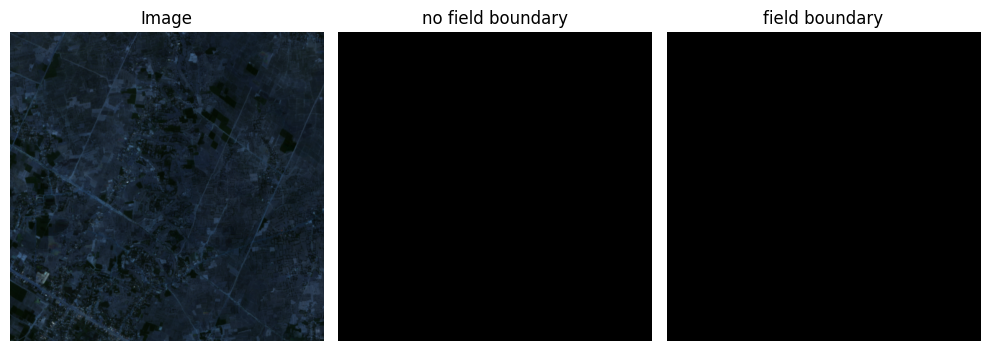

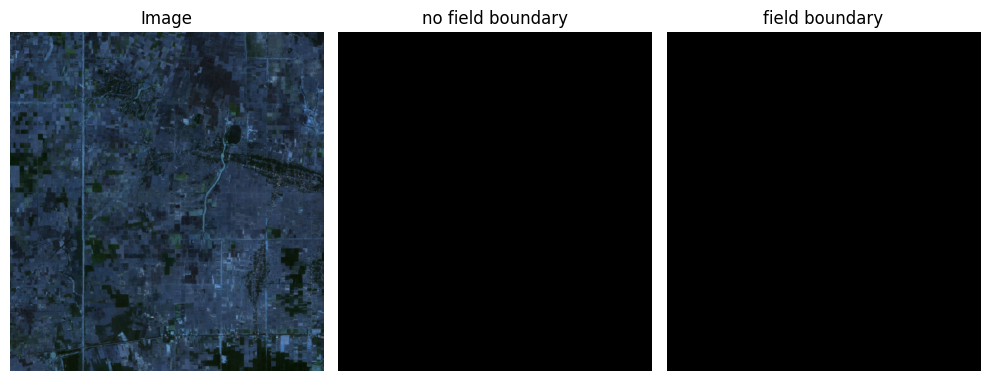

In [13]:
model_path = "/home/dragik/data/FAIR_EO/experiments/ai4smallfarms/checkpoint.pth.tar"
labels = ["no field boundary","field boundary"]
transform = MinMaxNormTranspose()
model.load_model(model_path)

image = image_loader('/home/dragik/data/FAIR_EO/ai4smallfarms/sentinel-2-asia/test/images/8_cambodia.tif')[:,:,:3]
img_min, img_max = image.min(), image.max()
image = (image - img_min) / (img_max - img_min + 1e-8)
fig = model.predict_masks(image, labels, transform)

image = image_loader('/home/dragik/data/FAIR_EO/ai4smallfarms/sentinel-2-asia/test/images/58_cambodia.tif')[:,:,:3]
img_min, img_max = image.min(), image.max()
image = (image - img_min) / (img_max - img_min + 1e-8)
fig = model.predict_masks(image, labels, transform)